# Reproduce Yu et al. Figure 8a — LER ~ TND from GenAI extractions

Each code cell below runs the full pipeline for **one language model**, keeping extraction methods separate (`direct_llm`, `workflow`, `MAS`).

**Inclusion rule**

1. **LER** — usable reported LER, else calculate from four yields (unit-normalized); else exclude  
2. **TND** — usable reported TND, else calculate from sowing/harvest dates; else exclude  
3. **Eligible for matching** only with final LER + final TND + mapped Study  
4. **Match** eligible rows 1:1 to GT on design fields only (no LER/TND/yields/dates). Multiple matched rows may share an `Experimental ID`; each GT row matches at most one GenAI row. Unmatched eligible rows are excluded from the regression.  
5. **Fit** `lme(LER_final ~ TND_final, random = ~1 | Study/Expt, method = "REML")`

A broken / jumped y-axis is used only when some LER values are ≥ 10; smaller values stay on a single axis.

Logic: `src/experimentutils/ler_prep.py`, `ler_reproduction.py`.  
Checkpoints: `outputs/ler_tnd_reproduction/` (raw GenAI CSVs untouched).

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", category=UserWarning)

repo_root = Path.cwd().resolve()
for p in [repo_root, *repo_root.parents]:
    if (p / "src").is_dir() and (p / "outputs").is_dir():
        repo_root = p
        break
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.experimentutils.ler_reproduction import (
    METHOD_PREFIXES,
    PUBLISHED_TND_COEF,
    ground_truth_baselines,
    list_model_tags,
    plot_figure8a_style,
    run_all_methods_for_model,
)

METHODS = list(METHOD_PREFIXES)
print("repo:", repo_root)
print("available models:")
for tag in list_model_tags():
    print(" -", tag)

repo: /home/com3dian/Github/meta_analysis_agents
available models:
 - google_gemini-2-5-flash_42fields
 - surf_Qwen-Qwen3-6-27B-FP8_42fields
 - surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields
 - surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields
 - surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields
 - surf_default-text-large_42fields
 - surf_mistralai-Mistral-Small-3-2-24B-Instruct-2506_42fields
 - surf_openai-gpt-oss-120b_42fields


## Ground-truth baselines

- **Published (studies 1–100):** reference coefficient ≈ 0.211  
- **Comparable (studies 1–90):** fair baseline for this corpus (papers 91–100 unmapped)

In [2]:
BASELINES = ground_truth_baselines()
rows = []
for name, fit in BASELINES.items():
    rows.append(fit.as_dict())
baseline_df = pd.DataFrame(rows)
display(baseline_df[
    [
        "model_tag",
        "tnd_coef",
        "tnd_se",
        "tnd_ci_low",
        "tnd_ci_high",
        "tnd_pvalue",
        "n_records",
        "n_studies",
        "n_experiments",
        "engine",
    ]
])
print(f"Published TND coefficient target ≈ {PUBLISHED_TND_COEF}")

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,model_tag,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,engine
0,published_1_100,0.211085,0.058629,0.096175,0.325996,0.000318,746,100,189,statsmodels
1,comparable_1_90,0.289556,0.062796,0.166478,0.412634,0.000004,626,90,159,statsmodels


Published TND coefficient target ≈ 0.211


In [3]:
def reproduce_one_llm(model_tag: str, *, methods=None, prefer_r: bool = True):
    """Run preparation + LME + Figure 8a plots for one model (all methods)."""
    results = run_all_methods_for_model(
        model_tag,
        methods=methods or METHODS,
        baselines=BASELINES,
        prefer_r=prefer_r,
        write_outputs=True,
        show_plot=False,
    )

    fit_rows = [results[m]["fit"].as_dict() for m in results]
    fit_df = pd.DataFrame(fit_rows)
    print(model_tag)
    display(
        fit_df[
            [
                "method",
                "tnd_coef",
                "tnd_se",
                "tnd_ci_low",
                "tnd_ci_high",
                "tnd_pvalue",
                "n_records",
                "n_studies",
                "n_experiments",
                "n_reported_ler",
                "n_calculated_ler",
                "n_excluded_ler",
                "engine",
            ]
        ]
    )

    for method, payload in results.items():
        summary = payload["summary"]
        print(
            f"\n{method}: eligible={summary.get('n_regression_eligible')} "
            f"matched={summary.get('n_matched')} analysis={summary.get('n_analysis')}"
        )
        print(
            f"  LER sources={summary['LER_source_counts']} | "
            f"TND sources={summary['TND_source_counts']}"
        )
        if summary.get("match_exclusion_reasons"):
            print("  match exclusions:", summary["match_exclusion_reasons"])
        if summary["LER_exclusion_reasons"]:
            print("  LER exclusions:", summary["LER_exclusion_reasons"])

    n = len(results)
    fig, axes = plt.subplots(1, n, figsize=(5.2 * n, 5.2), squeeze=False)
    for ax, method in zip(axes[0], results):
        payload = results[method]
        plot_figure8a_style(
            payload["analysis"],
            payload["fit"],
            baselines=BASELINES,
            ax=ax,
            title=f"{method}",
        )
    fig.suptitle(model_tag, y=1.02, fontsize=12)
    fig.tight_layout()
    plt.show()
    return results

## openai-gpt-oss-120b

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


surf_openai-gpt-oss-120b_42fields


/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,method,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,n_reported_ler,n_calculated_ler,n_excluded_ler,engine
0,direct_llm,0.667602,0.258998,0.159975,1.175229,0.009948,70,15,21,469,12,531,statsmodels
1,workflow,-0.443423,45.669123,-89.953260,89.066413,0.992253,25,5,6,418,10,551,statsmodels
2,MAS,0.539611,NaN,NaN,NaN,NaN,34,10,14,248,9,510,statsmodels



direct_llm: eligible=91 matched=70 analysis=70
  LER sources={'reported': 469, 'calculated_from_yields': 12, 'excluded': 531} | TND sources={'excluded': 806, 'calculated_from_dates': 206}
  match exclusions: {'missing_final_ler': 531, 'missing_final_tnd': 390, 'unmatched_eligible_row': 21}
  LER exclusions: {'missing_yield_value': 495, 'incompatible_yield_unit': 20, 'missing_sole_yield_2': 8, 'missing_yield_unit': 8}

workflow: eligible=50 matched=25 analysis=25
  LER sources={'excluded': 551, 'reported': 418, 'calculated_from_yields': 10} | TND sources={'excluded': 896, 'calculated_from_dates': 83}
  match exclusions: {'missing_final_ler': 551, 'missing_final_tnd': 378, 'unmatched_eligible_row': 25}
  LER exclusions: {'missing_intercrop_yield_2': 11, 'incompatible_yield_unit': 20, 'ambiguous_numeric_range': 2, 'missing_yield_value': 487, 'missing_yield_unit': 23, 'missing_sole_yield_2': 8}

MAS: eligible=43 matched=34 analysis=34
  LER sources={'excluded': 510, 'calculated_from_yield

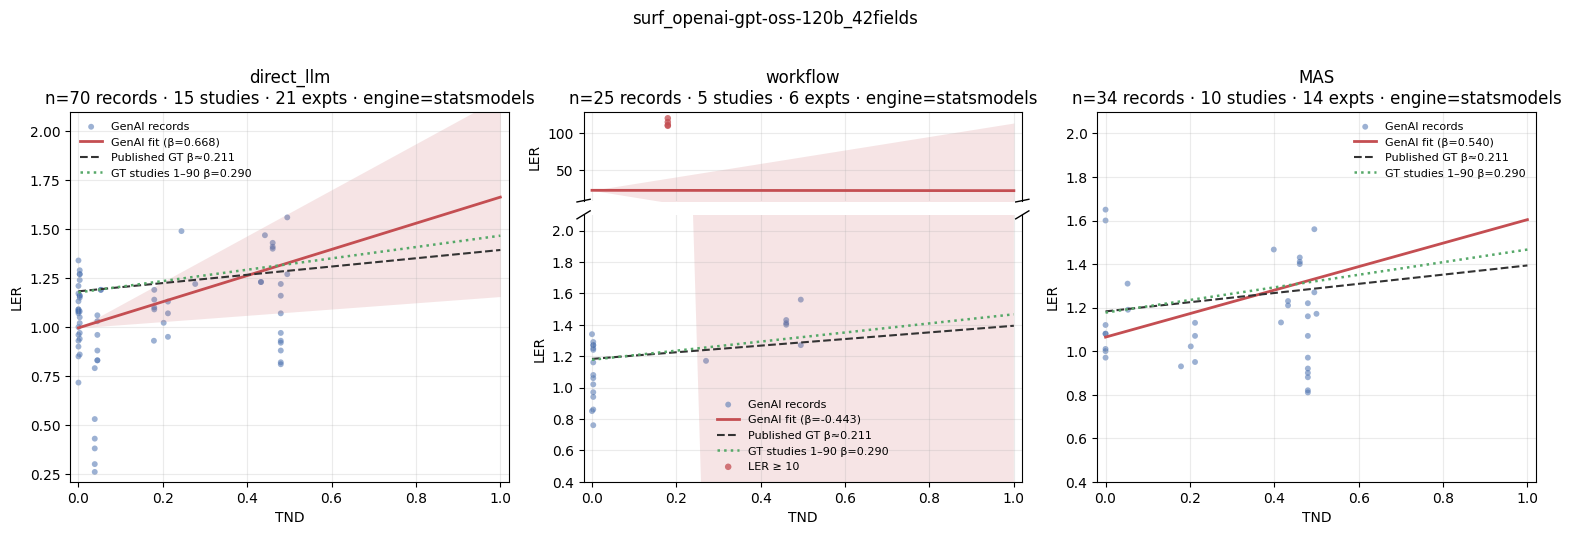

In [4]:
gpt_oss = reproduce_one_llm("surf_openai-gpt-oss-120b_42fields")

## Sehyo-Qwen3-5-122B-A10B-NVFP4

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields


/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


,method,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,n_reported_ler,n_calculated_ler,n_excluded_ler,engine
0,direct_llm,0.704577,0.217126,0.279019,1.130136,0.001174,92,21,26,447,115,208,statsmodels
1,workflow,-0.044974,0.280964,-0.595653,0.505706,0.872827,45,12,15,348,60,236,statsmodels
2,MAS,0.418754,0.506934,-0.574819,1.412326,0.408775,85,15,17,278,62,90,statsmodels



direct_llm: eligible=145 matched=92 analysis=92
  LER sources={'reported': 447, 'calculated_from_yields': 115, 'excluded': 208} | TND sources={'excluded': 543, 'calculated_from_dates': 227}
  match exclusions: {'missing_final_tnd': 417, 'missing_final_ler': 208, 'unmatched_eligible_row': 53}
  LER exclusions: {'missing_intercrop_yield_2': 20, 'missing_yield_value': 139, 'missing_sole_yield_1': 4, 'incompatible_yield_unit': 14, 'missing_sole_yield_2': 25, 'zero_sole_crop_yield': 6}

workflow: eligible=53 matched=45 analysis=45
  LER sources={'reported': 348, 'calculated_from_yields': 60, 'excluded': 236} | TND sources={'excluded': 556, 'calculated_from_dates': 88}
  match exclusions: {'missing_final_tnd': 355, 'missing_final_ler': 236, 'unmatched_eligible_row': 8}
  LER exclusions: {'incompatible_yield_unit': 22, 'missing_intercrop_yield_2': 20, 'missing_sole_yield_2': 19, 'missing_yield_value': 162, 'missing_sole_yield_1': 7, 'zero_sole_crop_yield': 6}

MAS: eligible=137 matched=85 an

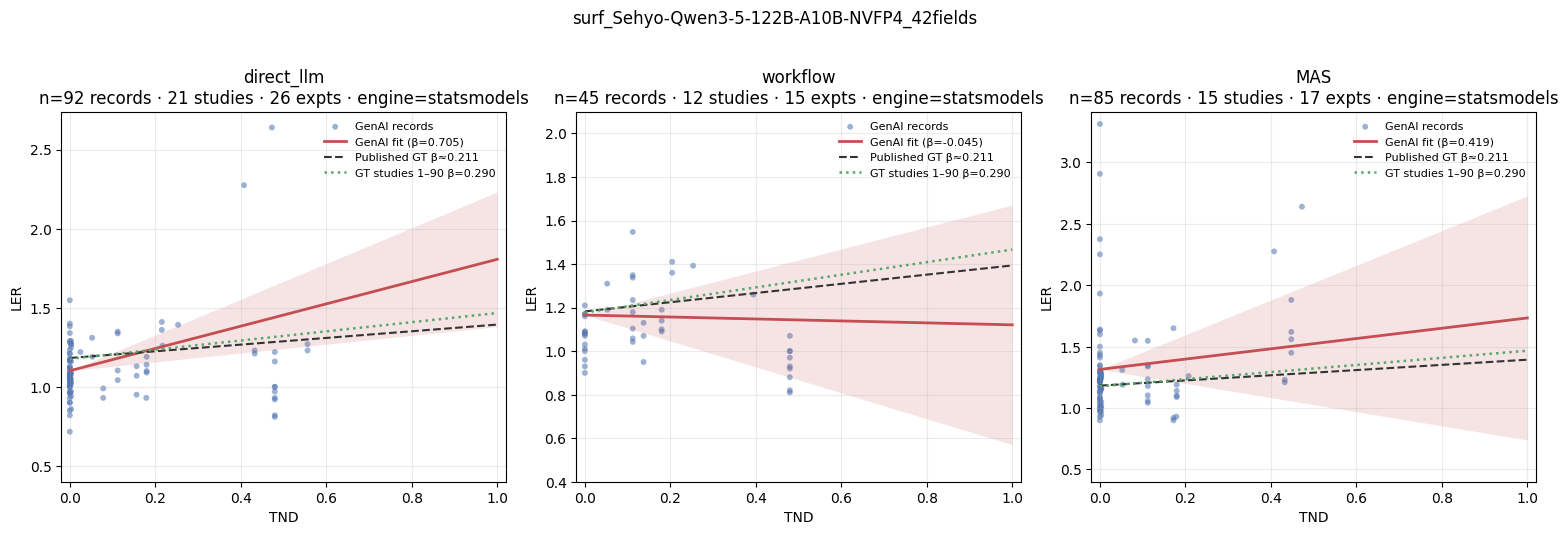

In [5]:
qwen122 = reproduce_one_llm("surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields")

## Qwen3-6-35B-A3B-FP8

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 2.654431
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/

surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields


/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,method,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,n_reported_ler,n_calculated_ler,n_excluded_ler,engine
0,direct_llm,0.689099,0.163533,0.368581,1.009617,0.000025,106,25,38,520,96,169,statsmodels
1,workflow,1.236095,0.402787,0.446648,2.025542,0.002149,49,12,16,399,92,181,statsmodels
2,MAS,0.478832,0.214258,0.058894,0.898770,0.025428,105,20,33,340,85,197,statsmodels



direct_llm: eligible=140 matched=106 analysis=106
  LER sources={'reported': 520, 'calculated_from_yields': 96, 'excluded': 169} | TND sources={'excluded': 623, 'calculated_from_dates': 162}
  match exclusions: {'missing_final_tnd': 476, 'missing_final_ler': 169, 'unmatched_eligible_row': 34}
  LER exclusions: {'missing_intercrop_yield_2': 12, 'missing_yield_value': 109, 'missing_sole_yield_2': 19, 'missing_sole_yield_1': 17, 'incompatible_yield_unit': 6, 'zero_sole_crop_yield': 6}

workflow: eligible=65 matched=49 analysis=49
  LER sources={'reported': 399, 'calculated_from_yields': 92, 'excluded': 181} | TND sources={'excluded': 590, 'calculated_from_dates': 82}
  match exclusions: {'missing_final_tnd': 426, 'missing_final_ler': 181, 'unmatched_eligible_row': 16}
  LER exclusions: {'missing_yield_value': 128, 'unparseable_reported_ler': 6, 'missing_intercrop_yield_2': 6, 'missing_sole_yield_2': 25, 'incompatible_yield_unit': 16}

MAS: eligible=152 matched=105 analysis=105
  LER sour

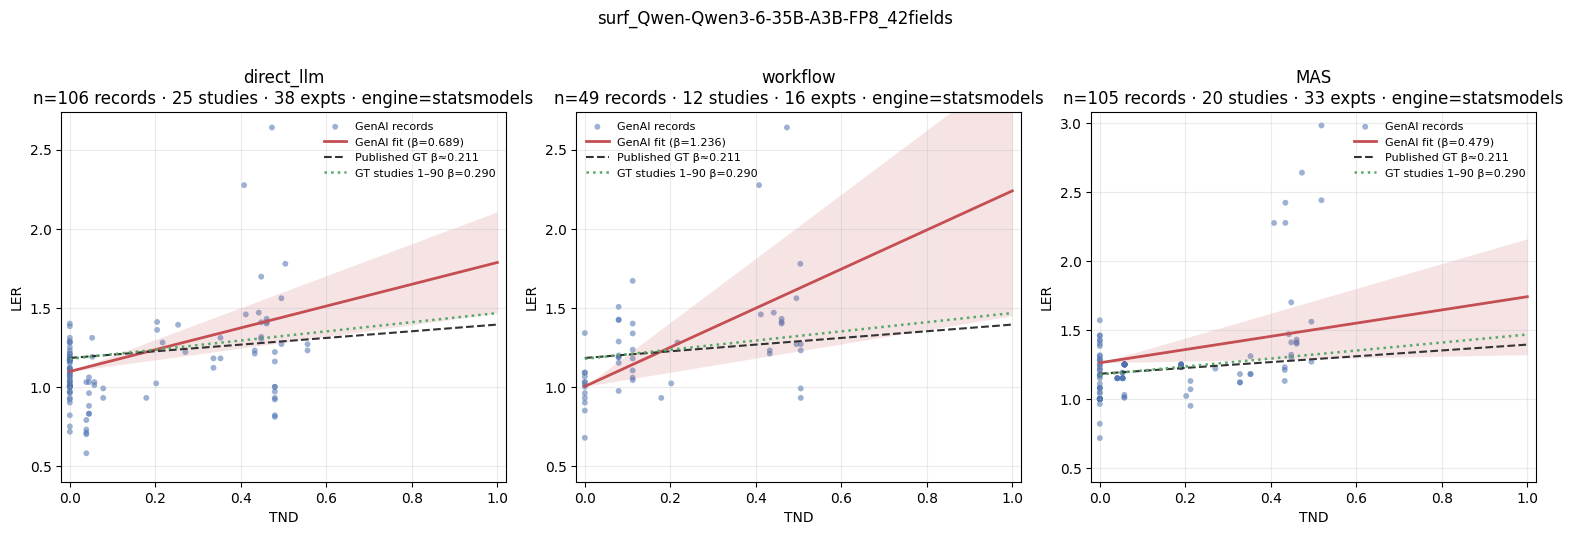

In [6]:
qwen35 = reproduce_one_llm("surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields")

## Qwen3-6-27B-FP8

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1533: RuntimeWarning: divide by zero encountered in log
  cov_aug_logdet = cov_re_logdet + np.sum(np.log(vc_var))
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1537: RuntimeWarning: divide by zero encountered in divide
  solver = _smw_solver(1., ex_r, ex2_r, cov_re_inv, 1 / vc_var)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1542: RuntimeWarning: divide by zero encountered in divide
  ld = _smw_logdet(1., ex_r, ex2_r, cov_re_inv, 1 / vc_var,
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regre

surf_Qwen-Qwen3-6-27B-FP8_42fields


/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,method,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,n_reported_ler,n_calculated_ler,n_excluded_ler,engine
0,direct_llm,0.295279,0.288664,-0.270492,0.861051,0.306347,47,10,16,199,72,50,statsmodels
1,workflow,-0.343890,0.496896,-1.317789,0.630009,0.488890,5,2,3,157,13,68,statsmodels
2,MAS,0.189231,0.308663,-0.415737,0.794199,0.539832,31,8,11,205,40,72,statsmodels



direct_llm: eligible=49 matched=47 analysis=47
  LER sources={'reported': 199, 'calculated_from_yields': 72, 'excluded': 50} | TND sources={'excluded': 265, 'calculated_from_dates': 56}
  match exclusions: {'missing_final_tnd': 222, 'missing_final_ler': 50, 'unmatched_eligible_row': 2}
  LER exclusions: {'missing_yield_value': 31, 'missing_sole_yield_2': 7, 'incompatible_yield_unit': 12}

workflow: eligible=5 matched=5 analysis=5
  LER sources={'reported': 157, 'excluded': 68, 'calculated_from_yields': 13} | TND sources={'excluded': 233, 'calculated_from_dates': 5}
  match exclusions: {'missing_final_tnd': 165, 'missing_final_ler': 68}
  LER exclusions: {'missing_yield_value': 40, 'incompatible_yield_unit': 22, 'missing_intercrop_yield_1': 6}

MAS: eligible=36 matched=31 analysis=31
  LER sources={'reported': 205, 'calculated_from_yields': 40, 'excluded': 72} | TND sources={'excluded': 269, 'calculated_from_dates': 48}
  match exclusions: {'missing_final_tnd': 209, 'missing_final_ler'

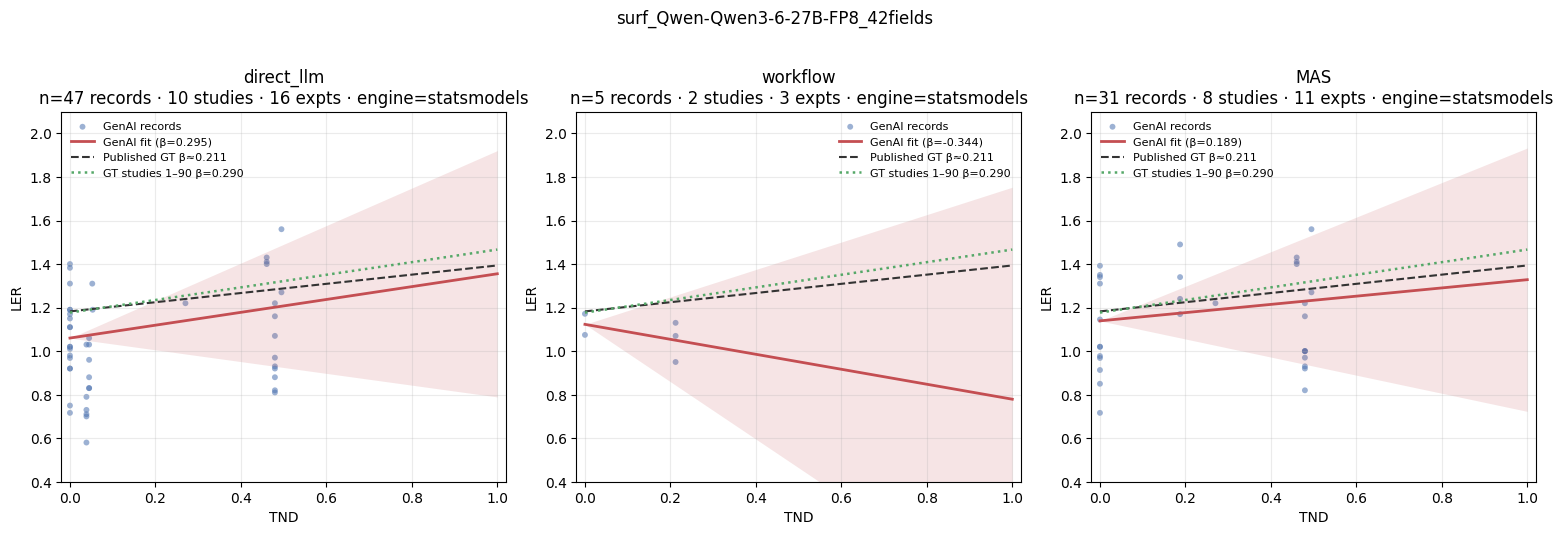

In [7]:
qwen27 = reproduce_one_llm("surf_Qwen-Qwen3-6-27B-FP8_42fields")

## RedHatAI-gemma-4-31B-it-NVFP4

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 1.342523
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/

surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields


/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


,method,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,n_reported_ler,n_calculated_ler,n_excluded_ler,engine
0,direct_llm,0.500573,0.180979,0.145861,0.855285,0.005676,53,15,19,279,83,182,statsmodels
1,workflow,0.058793,0.260739,-0.452246,0.569832,0.821602,25,7,9,312,39,191,statsmodels
2,MAS,0.535268,2.873977,-5.097624,6.168161,0.852251,46,13,17,281,66,168,statsmodels



direct_llm: eligible=74 matched=53 analysis=53
  LER sources={'reported': 279, 'calculated_from_yields': 83, 'excluded': 182} | TND sources={'excluded': 417, 'calculated_from_dates': 127}
  match exclusions: {'missing_final_tnd': 288, 'missing_final_ler': 182, 'unmatched_eligible_row': 21}
  LER exclusions: {'missing_intercrop_yield_2': 12, 'missing_yield_value': 123, 'incompatible_yield_unit': 20, 'missing_sole_yield_2': 26, 'missing_intercrop_yield_1': 1}

workflow: eligible=37 matched=25 analysis=25
  LER sources={'reported': 312, 'calculated_from_yields': 39, 'excluded': 191} | TND sources={'excluded': 473, 'calculated_from_dates': 68, 'reported': 1}
  match exclusions: {'missing_final_tnd': 314, 'missing_final_ler': 191, 'unmatched_eligible_row': 12}
  LER exclusions: {'missing_intercrop_yield_2': 6, 'missing_yield_value': 137, 'incompatible_yield_unit': 39, 'missing_sole_yield_2': 3, 'missing_intercrop_yield_1': 6}

MAS: eligible=62 matched=46 analysis=46
  LER sources={'reporte

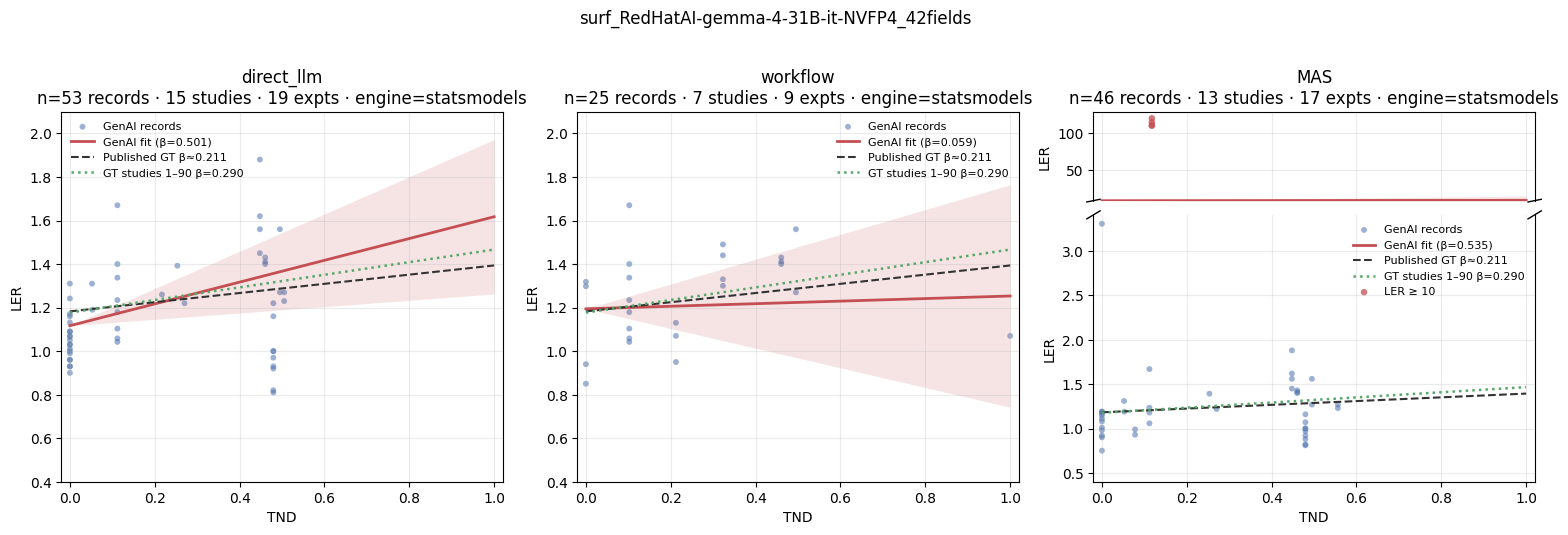

In [8]:
gemma31 = reproduce_one_llm("surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields")

## default-text-large

/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 2.443605
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/com3dian/miniconda3/envs/sam2/lib/python3.12/

surf_default-text-large_42fields


/home/com3dian/miniconda3/envs/sam2/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,method,tnd_coef,tnd_se,tnd_ci_low,tnd_ci_high,tnd_pvalue,n_records,n_studies,n_experiments,n_reported_ler,n_calculated_ler,n_excluded_ler,engine
0,direct_llm,0.470476,0.215776,0.047562,0.893390,0.029229,70,14,21,412,35,563,statsmodels
1,workflow,0.005523,0.337127,-0.655235,0.666281,0.986929,13,6,10,442,17,564,statsmodels
2,MAS,-0.005001,0.169263,-0.336750,0.326748,0.976428,33,10,12,214,2,504,statsmodels



direct_llm: eligible=100 matched=70 analysis=70
  LER sources={'calculated_from_yields': 35, 'excluded': 563, 'reported': 412} | TND sources={'excluded': 877, 'calculated_from_dates': 133}
  match exclusions: {'missing_final_ler': 563, 'missing_final_tnd': 347, 'unmatched_eligible_row': 30}
  LER exclusions: {'missing_yield_value': 516, 'incompatible_yield_unit': 39, 'missing_sole_yield_2': 8}

workflow: eligible=27 matched=13 analysis=13
  LER sources={'reported': 442, 'excluded': 564, 'calculated_from_yields': 17} | TND sources={'excluded': 962, 'calculated_from_dates': 61}
  match exclusions: {'missing_final_ler': 564, 'missing_final_tnd': 432, 'unmatched_eligible_row': 14}
  LER exclusions: {'incompatible_yield_unit': 26, 'missing_yield_value': 488, 'missing_intercrop_yield_2': 2, 'missing_yield_unit': 40, 'missing_sole_yield_2': 8}

MAS: eligible=46 matched=33 analysis=33
  LER sources={'reported': 214, 'excluded': 504, 'calculated_from_yields': 2} | TND sources={'excluded': 614,

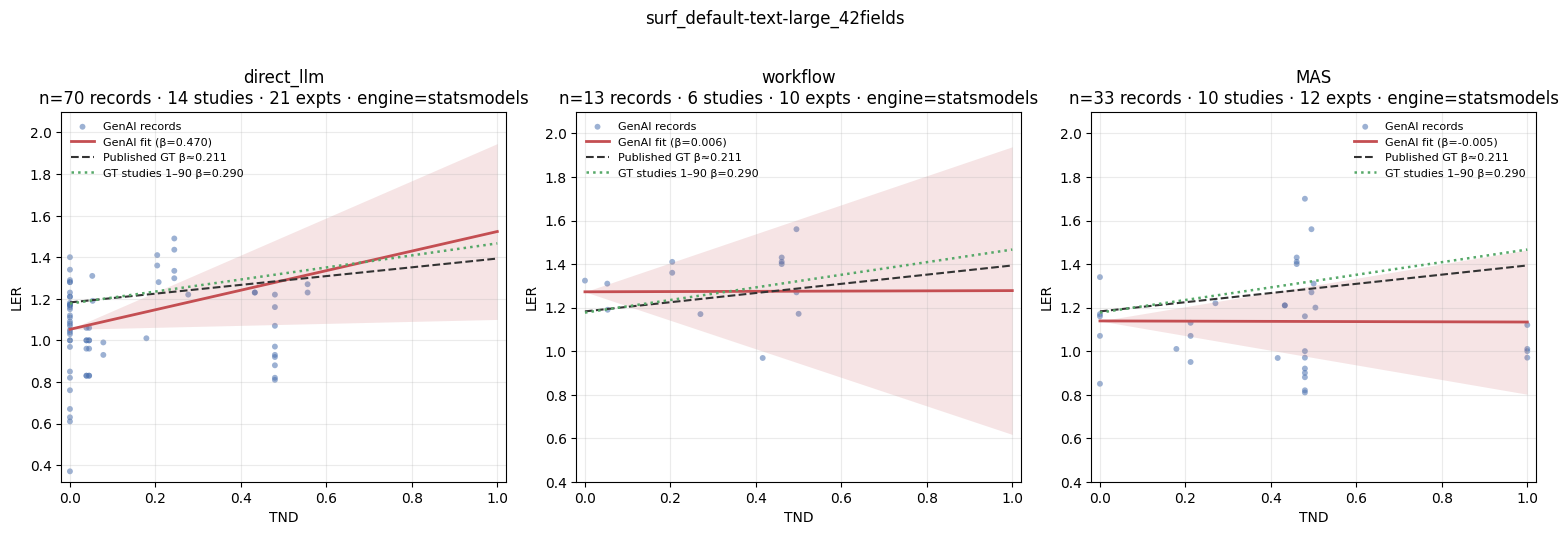

In [9]:
default_text = reproduce_one_llm("surf_default-text-large_42fields")

## Cross-model summary

Compare TND coefficients against the published ≈0.211 and the studies 1–90 GT baseline.

In [10]:
all_runs = {
    "surf_openai-gpt-oss-120b_42fields": gpt_oss,
    "surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields": gemma31,
    "surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields": qwen35,
    "surf_Qwen-Qwen3-6-27B-FP8_42fields": qwen27,
    "surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields": qwen122,
    "surf_default-text-large_42fields": default_text,
}

summary_rows = []
for tag, methods in all_runs.items():
    for method, payload in methods.items():
        d = payload["fit"].as_dict()
        d["delta_vs_published"] = d["tnd_coef"] - BASELINES["published_1_100"].tnd_coef
        d["delta_vs_1_90"] = d["tnd_coef"] - BASELINES["comparable_1_90"].tnd_coef
        summary_rows.append(d)

summary_df = pd.DataFrame(summary_rows)
display(
    summary_df[
        [
            "model_tag",
            "method",
            "tnd_coef",
            "delta_vs_published",
            "delta_vs_1_90",
            "n_records",
            "n_studies",
            "n_reported_ler",
            "n_calculated_ler",
            "n_excluded_ler",
        ]
    ].sort_values(["method", "tnd_coef"], ascending=[True, False])
)

,model_tag,method,tnd_coef,delta_vs_published,delta_vs_1_90,n_records,n_studies,n_reported_ler,n_calculated_ler,n_excluded_ler
2,surf_openai-gpt-oss-120b_42fields,MAS,0.539611,0.328526,0.250055,34,10,248,9,510
5,surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields,MAS,0.535268,0.324183,0.245712,46,13,281,66,168
8,surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields,MAS,0.478832,0.267747,0.189276,105,20,340,85,197
14,surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields,MAS,0.418754,0.207669,0.129198,85,15,278,62,90
11,surf_Qwen-Qwen3-6-27B-FP8_42fields,MAS,0.189231,-0.021854,-0.100325,31,8,205,40,72
17,surf_default-text-large_42fields,MAS,-0.005001,-0.216086,-0.294557,33,10,214,2,504
12,surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields,direct_llm,0.704577,0.493492,0.415021,92,21,447,115,208
6,surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields,direct_llm,0.689099,0.478014,0.399543,106,25,520,96,169
0,surf_openai-gpt-oss-120b_42fields,direct_llm,0.667602,0.456517,0.378046,70,15,469,12,531
3,surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields,direct_llm,0.500573,0.289488,0.211017,53,15,279,83,182


## Six-model overview

Landscape `figure*` (2×3), shared LER range 0–2. Off-scale observations are marked at the top edge; fully off-scale fits appear in a small inset with its own LER scale.


saved /home/com3dian/Github/meta_analysis_agents/outputs/ler_tnd_reproduction/ler_tnd_six_model_overview.png
saved /home/com3dian/Github/meta_analysis_agents/outputs/ler_tnd_reproduction/ler_tnd_six_model_overview.pdf


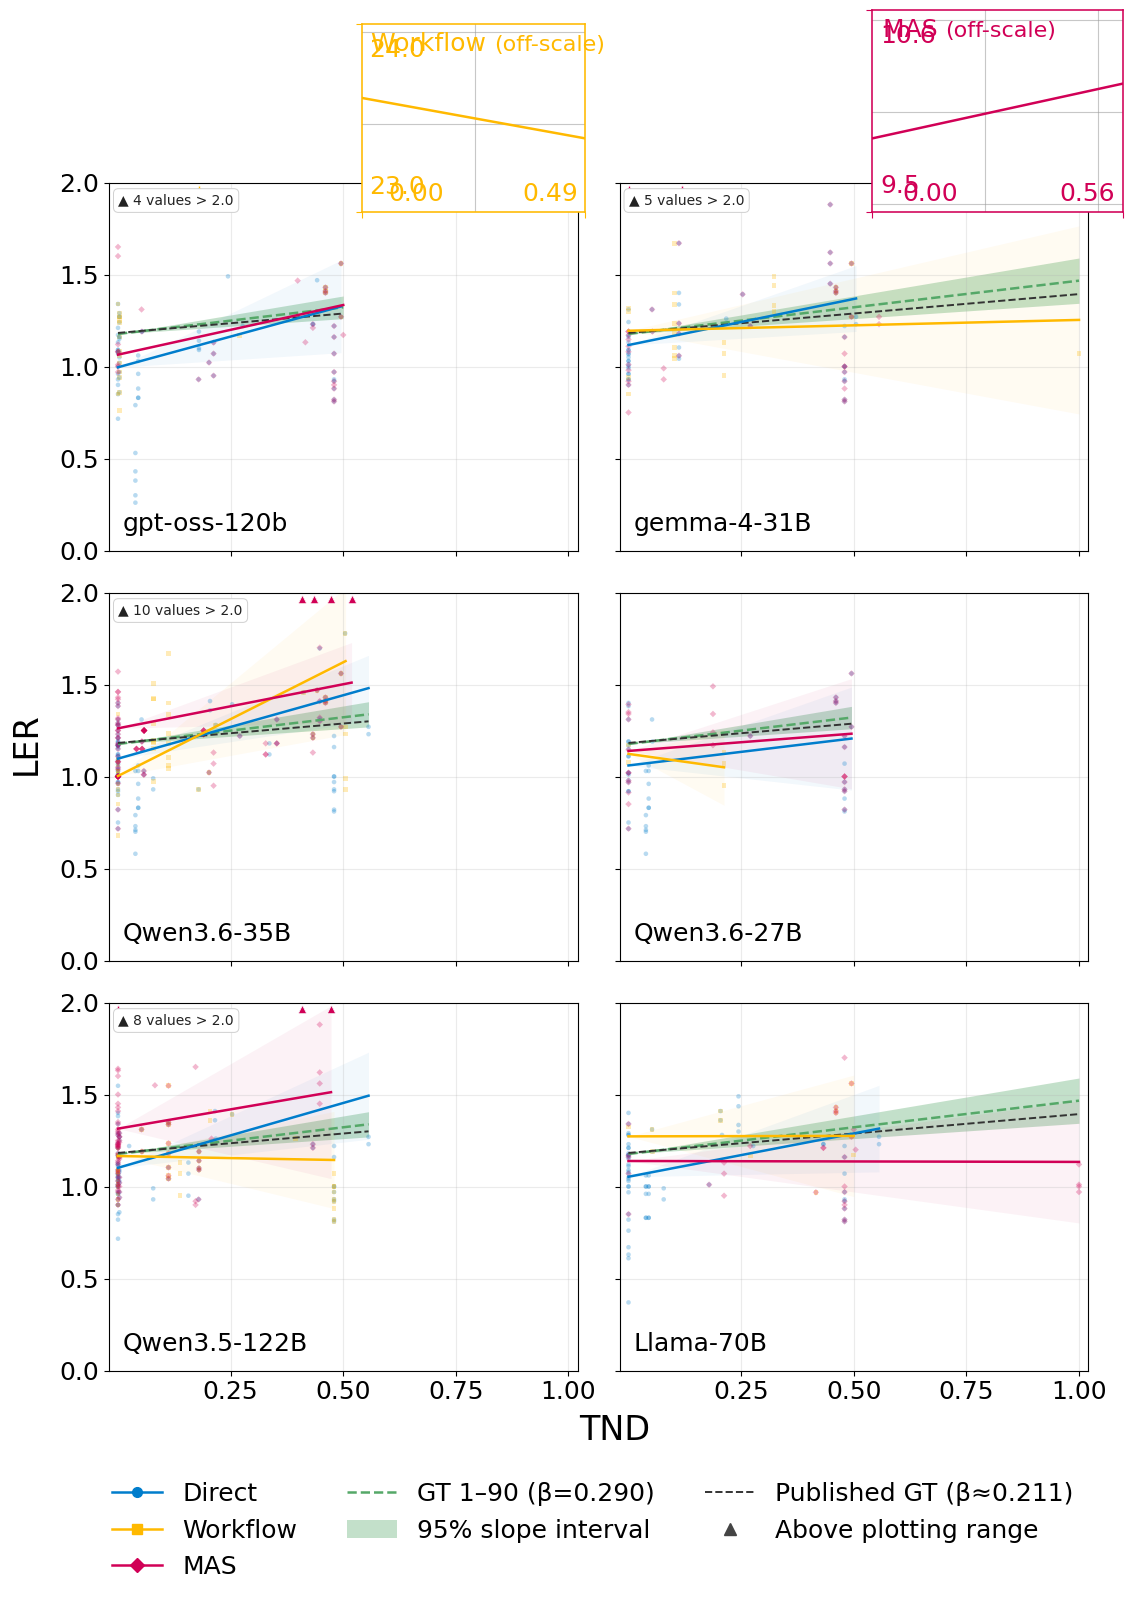

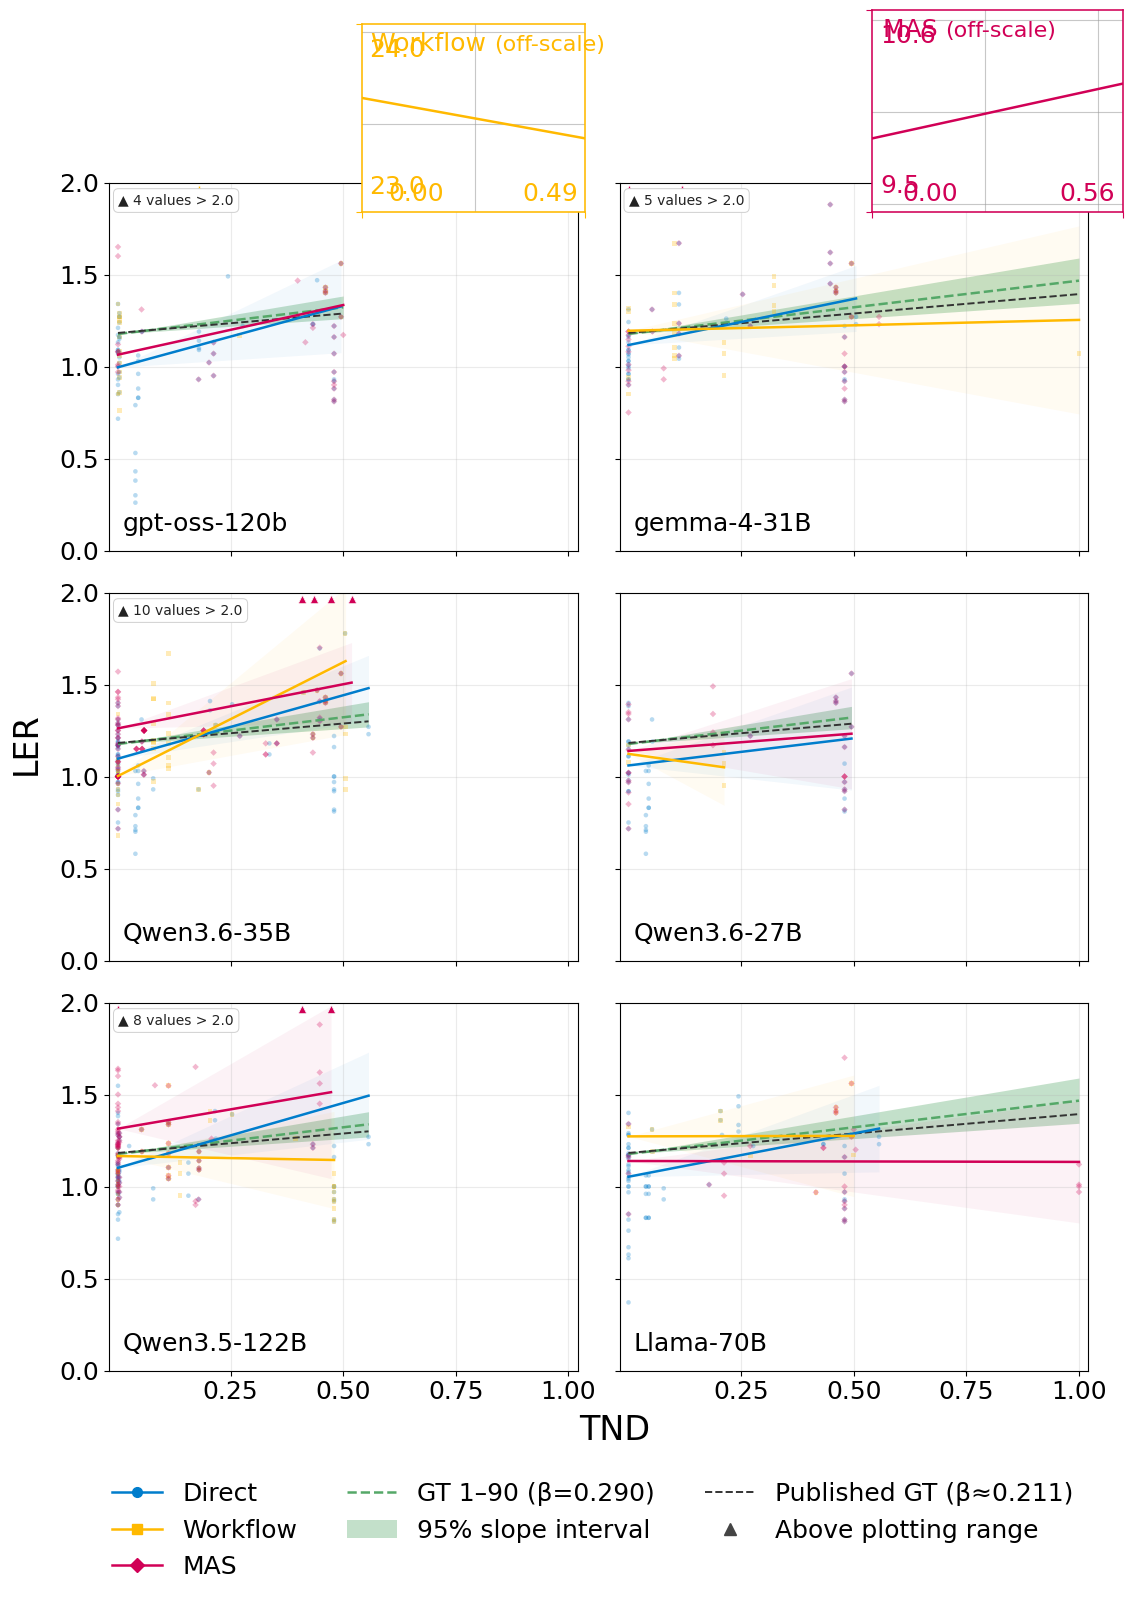

In [11]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

METHOD_PLOT_COLORS = {
    "direct_llm": "#007DCC",
    "workflow": "#FFB900",
    "MAS": "#D10056",
}
METHOD_MARKERS = {
    "direct_llm": "o",
    "workflow": "s",
    "MAS": "D",
}
METHOD_LABELS = {
    "direct_llm": "Direct",
    "workflow": "Workflow",
    "MAS": "MAS",
}
GT_COLOR = "#55A868"
GT_PUB_COLOR = "#333333"

MODEL_DISPLAY = {
    "surf_openai-gpt-oss-120b_42fields": "gpt-oss-120b",
    "surf_RedHatAI-gemma-4-31B-it-NVFP4_42fields": "gemma-4-31B",
    "surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields": "Qwen3.6-35B",
    "surf_Qwen-Qwen3-6-27B-FP8_42fields": "Qwen3.6-27B",
    "surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields": "Qwen3.5-122B",
    "surf_default-text-large_42fields": "Llama-70B",
}

TITLE_FONTSIZE = 18
AXIS_LABEL_FONTSIZE = 24
TICK_LABELSIZE = 18
LEGEND_FONTSIZE = 18
POINT_SIZE = 11
POINT_ALPHA = 0.28
Y_MIN = 0.0
Y_MAX = 2.0
# Match the main-panel grid: 0.25 TND × 0.5 LER cells.
X_GRID_STEP = 0.25
Y_GRID_STEP = 0.5


def _short_model_title(tag: str) -> str:
    return MODEL_DISPLAY.get(tag, tag.removeprefix("surf_").removesuffix("_42fields"))


def _collect_method_points(method_results: dict, methods: tuple[str, ...]) -> pd.DataFrame:
    parts = []
    for method in methods:
        if method not in method_results:
            continue
        df = method_results[method].get("analysis")
        if df is None or df.empty:
            continue
        sub = pd.DataFrame(
            {
                "TND": pd.to_numeric(df["TND_final"], errors="coerce"),
                "LER": pd.to_numeric(df["LER_final"], errors="coerce"),
                "method": method,
            }
        ).dropna()
        if not sub.empty:
            parts.append(sub)
    if not parts:
        return pd.DataFrame(columns=["TND", "LER", "method"])
    return pd.concat(parts, ignore_index=True)


def _tnd_range(points: pd.DataFrame, method: str) -> tuple[float, float] | None:
    sub = points.loc[points["method"] == method, "TND"] if len(points) else pd.Series(dtype=float)
    if sub.empty:
        return None
    lo, hi = float(sub.min()), float(sub.max())
    if not (math.isfinite(lo) and math.isfinite(hi)):
        return None
    if lo == hi:
        pad = 0.02
        return max(0.0, lo - pad), min(1.0, hi + pad)
    return lo, hi


def _fit_clip_info(intercept: float, coef: float, x0: float, x1: float, y_min: float, y_max: float):
    """Clip y = intercept + coef * x to [y_min, y_max] on x in [x0, x1]."""
    y0 = intercept + coef * x0
    y1 = intercept + coef * x1
    entire_above = min(y0, y1) > y_max
    entire_below = max(y0, y1) < y_min
    xs = [x0, x1]
    if coef != 0:
        for yb in (y_min, y_max):
            xc = (yb - intercept) / coef
            if x0 <= xc <= x1:
                xs.append(xc)
    xs = sorted(set(xs))
    segs = []
    for xa, xb in zip(xs[:-1], xs[1:]):
        y_mid = intercept + coef * (0.5 * (xa + xb))
        if y_min <= y_mid <= y_max:
            segs.append((xa, xb))
    x_cross_hi = None
    if coef != 0:
        xc = (y_max - intercept) / coef
        if x0 <= xc <= x1 and not entire_above:
            if max(y0, y1) > y_max:
                x_cross_hi = xc
    return segs, x_cross_hi, entire_above, entire_below


def _plot_effect(
    ax,
    *,
    intercept: float,
    coef: float,
    se: float,
    x0: float,
    x1: float,
    y_min: float,
    y_max: float,
    color: str,
    ls: str = "-",
    lw: float = 2.0,
    band_alpha: float = 0.18,
) -> tuple[bool, float | None]:
    """Draw slope band + clipped line over [x0, x1]. Returns (entirely_outside, x_cross_hi)."""
    segs, x_cross, above, below = _fit_clip_info(intercept, coef, x0, x1, y_min, y_max)
    if above or below:
        return True, None
    x = np.linspace(x0, x1, 80)
    if math.isfinite(se) and se > 0:
        y_lo = intercept + (coef - 1.96 * se) * x
        y_hi = intercept + (coef + 1.96 * se) * x
        ax.fill_between(
            x,
            np.clip(y_lo, y_min, y_max),
            np.clip(y_hi, y_min, y_max),
            color=color,
            alpha=band_alpha,
            linewidth=0,
            zorder=1,
            clip_on=True,
        )
    for xa, xb in segs:
        ax.plot(
            [xa, xb],
            [intercept + coef * xa, intercept + coef * xb],
            color=color,
            ls=ls,
            lw=lw,
            zorder=4,
            clip_on=True,
        )
    if x_cross is not None:
        ax.plot(
            x_cross,
            y_max - 0.03,
            marker="^",
            color=color,
            markersize=7,
            markeredgecolor="white",
            markeredgewidth=0.4,
            zorder=8,
            clip_on=False,
        )
    return False, x_cross


def _add_offscale_count_badge(ax, n_above: int, y_max: float) -> None:
    ax.text(
        0.02,
        0.97,
        f"▲ {n_above} values > {y_max:.1f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=10,
        color="#222222",
        zorder=10,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": "white",
            "edgecolor": "#d0d0d0",
            "linewidth": 0.7,
            "alpha": 1.0,
        },
    )


def _fmt_inset_tick(v: float) -> str:
    """Compact tick text; use K when |v| >= 1000, one decimal when |v| >= 2."""
    if not math.isfinite(v):
        return ""
    if abs(v) >= 1000:
        return f"{v / 1000:.1f}K"
    if abs(v) >= 2.0:
        return f"{v:.1f}"
    return f"{v:.2f}"


def _add_offscale_fit_inset(fig, ax, fits: list[dict]) -> None:
    """Off-scale inset: same physical unit scale as the parent; grey unit grid; edge labels only."""
    if not fits:
        return
    bbox = ax.get_position()
    px0, px1 = ax.get_xlim()
    py0, py1 = ax.get_ylim()
    parent_dx = px1 - px0
    parent_dy = py1 - py0
    if parent_dx <= 0 or parent_dy <= 0:
        return

    series = []
    y_vals = []
    for f in fits:
        x = np.linspace(f["x0"], f["x1"], 80)
        y = f["intercept"] + f["coef"] * x
        series.append((x, y, f))
        y_vals.append(y)
    y_all = np.concatenate(y_vals)
    y_lo, y_hi = float(np.min(y_all)), float(np.max(y_all))
    x_lo = min(f["x0"] for f in fits)
    x_hi = max(f["x1"] for f in fits)
    if y_hi <= y_lo:
        y_hi = y_lo + 1e-3
    if x_hi <= x_lo:
        x_hi = x_lo + 1e-3
    pad = max(0.4, 0.10 * max(y_hi - y_lo, 1.0))
    ylim_lo, ylim_hi = y_lo - pad, y_hi + pad
    # Size the inset so 1 TND / 1 LER occupies the same physical area as in the parent.
    w = (x_hi - x_lo) / parent_dx * bbox.width
    h = (ylim_hi - ylim_lo) / parent_dy * bbox.height
    x0 = bbox.x0 + 0.54 * bbox.width
    y0 = bbox.y0 + 0.92 * bbox.height
    inset = fig.add_axes([x0, y0, w, h])
    inset.set_facecolor("white")
    inset.patch.set_alpha(1.0)
    inset.set_zorder(9)
    inset.patch.set_zorder(9)

    for x, y, f in series:
        inset.plot(x, y, color=f["color"], lw=1.8, label=f["label"], zorder=2)

    inset.set_xlim(x_lo, x_hi)
    inset.set_ylim(ylim_lo, ylim_hi)
    inset.set_xticks([x_lo, x_hi])
    inset.set_yticks([ylim_lo, ylim_hi])
    inset.set_xticklabels(
        [_fmt_inset_tick(x_lo), _fmt_inset_tick(x_hi)],
        fontsize=TICK_LABELSIZE,
    )
    inset.set_yticklabels(
        [_fmt_inset_tick(ylim_lo), _fmt_inset_tick(ylim_hi)],
        fontsize=TICK_LABELSIZE,
    )
    inset.xaxis.set_minor_locator(MultipleLocator(X_GRID_STEP))
    inset.yaxis.set_minor_locator(MultipleLocator(Y_GRID_STEP))
    inset.tick_params(which="minor", length=0, labelbottom=False, labelleft=False)
    inset.set_axisbelow(True)
    inset.grid(False, which="major")
    inset.grid(True, which="minor", color="#9a9a9a", alpha=0.55, linewidth=0.8)

    if len(fits) == 1:
        f = fits[0]
        inset_color = f["color"]
        inset_name = f["label"]
        spine_lw = 1.15
    else:
        inset_color = "#555555"
        inset_name = ""
        inset.legend(fontsize=7, loc="best", frameon=False, handlelength=1.4)
        spine_lw = 1.0
    title_parts = []
    if inset_name:
        title_parts.append(
            TextArea(f"{inset_name} ", textprops={"color": inset_color, "size": LEGEND_FONTSIZE})
        )
    title_parts.append(
        TextArea("(off-scale)", textprops={"color": inset_color, "size": LEGEND_FONTSIZE - 2})
    )
    inset.add_artist(
        AnnotationBbox(
            HPacker(children=title_parts, align="baseline", pad=0, sep=0),
            (0.04, 0.96),
            xycoords="axes fraction",
            frameon=False,
            box_alignment=(0.0, 1.0),
            pad=0,
            zorder=11,
        )
    )
    for spine in inset.spines.values():
        spine.set_color(inset_color)
        spine.set_linewidth(spine_lw)
    inset.tick_params(
        axis="both",
        which="major",
        labelsize=TICK_LABELSIZE,
        length=4,
        pad=2,
        colors=inset_color,
        labelcolor=inset_color,
    )
    # Outside the box, but stay within the inset's height (y) and width (x).
    ylabs = inset.get_yticklabels()
    if len(ylabs) >= 2:
        ylabs[0].set_verticalalignment("bottom")
        ylabs[1].set_verticalalignment("top")
    xlabs = inset.get_xticklabels()
    if len(xlabs) >= 2:
        xlabs[0].set_horizontalalignment("left")
        xlabs[1].set_horizontalalignment("right")
    for lab in list(ylabs) + list(xlabs):
        lab.set_fontsize(TICK_LABELSIZE)
        lab.set_color(inset_color)
        lab.set_clip_on(False)


def plot_six_model_overview(
    runs: dict,
    baselines: dict,
    *,
    methods=("direct_llm", "workflow", "MAS"),
    y_min: float = Y_MIN,
    y_max: float = Y_MAX,
    save_dir: Path | None = None,
):
    """3×2 portrait figure*: shared y-limits, overflow triangles, observed-TND fits."""
    tags = list(runs.keys())
    fig, axes = plt.subplots(3, 2, figsize=(11.0, 16.5), sharex=True, sharey=True)
    # Equal physical gaps between panels (wspace/hspace are relative to axis size).
    fig_w, fig_h = fig.get_size_inches()
    left, right, bottom, top = 0.10, 0.99, 0.12, 0.84
    gap_in = 0.42
    ax_w_in = ((right - left) * fig_w - 1 * gap_in) / 2
    ax_h_in = ((top - bottom) * fig_h - 2 * gap_in) / 3
    fig.subplots_adjust(
        left=left,
        right=right,
        bottom=bottom,
        top=top,
        wspace=gap_in / ax_w_in,
        hspace=gap_in / ax_h_in,
    )
    gt = baselines["comparable_1_90"]
    pub = baselines.get("published_1_100")
    pending_insets: list[tuple] = []

    for ax, tag in zip(axes.ravel(), tags):
        method_results = runs[tag]
        points = _collect_method_points(method_results, methods)
        in_range = (
            points.loc[points["LER"].between(y_min, y_max, inclusive="both")]
            if len(points)
            else points
        )
        above = points.loc[points["LER"] > y_max] if len(points) else points

        for method in methods:
            sub = in_range.loc[in_range["method"] == method] if len(in_range) else in_range
            if sub.empty:
                continue
            ax.scatter(
                sub["TND"],
                sub["LER"],
                s=POINT_SIZE,
                alpha=POINT_ALPHA,
                color=METHOD_PLOT_COLORS[method],
                marker=METHOD_MARKERS[method],
                edgecolors="none",
                zorder=2.5,
            )

        if len(above):
            for method, sub in above.groupby("method", sort=False):
                ax.scatter(
                    sub["TND"],
                    np.full(len(sub), y_max - 0.035),
                    s=36,
                    marker="^",
                    color=METHOD_PLOT_COLORS.get(method, "steelblue"),
                    edgecolors="white",
                    linewidths=0.5,
                    zorder=8,
                    clip_on=False,
                )
            _add_offscale_count_badge(ax, int(len(above)), y_max)

        if len(points):
            gt_x0, gt_x1 = float(points["TND"].min()), float(points["TND"].max())
        else:
            gt_x0, gt_x1 = 0.0, 1.0
        if gt_x0 == gt_x1:
            gt_x0, gt_x1 = max(0.0, gt_x0 - 0.02), min(1.0, gt_x1 + 0.02)

        if math.isfinite(gt.intercept) and math.isfinite(gt.tnd_coef):
            _plot_effect(
                ax,
                intercept=gt.intercept,
                coef=gt.tnd_coef,
                se=gt.tnd_se,
                x0=gt_x0,
                x1=gt_x1,
                y_min=y_min,
                y_max=y_max,
                color=GT_COLOR,
                ls="--",
                lw=1.8,
                band_alpha=0.35,
            )
        if pub is not None and math.isfinite(pub.intercept) and math.isfinite(pub.tnd_coef):
            _plot_effect(
                ax,
                intercept=pub.intercept,
                coef=pub.tnd_coef,
                se=float("nan"),
                x0=gt_x0,
                x1=gt_x1,
                y_min=y_min,
                y_max=y_max,
                color=GT_PUB_COLOR,
                ls="--",
                lw=1.4,
                band_alpha=0.0,
            )

        offscale_fits = []
        for method in methods:
            if method not in method_results:
                continue
            fit = method_results[method]["fit"]
            if not (math.isfinite(fit.intercept) and math.isfinite(fit.tnd_coef)):
                continue
            xr = _tnd_range(points, method)
            if xr is None:
                continue
            x0, x1 = xr
            se = fit.tnd_se if math.isfinite(getattr(fit, "tnd_se", float("nan"))) else float("nan")
            outside, _cross = _plot_effect(
                ax,
                intercept=fit.intercept,
                coef=fit.tnd_coef,
                se=se,
                x0=x0,
                x1=x1,
                y_min=y_min,
                y_max=y_max,
                color=METHOD_PLOT_COLORS[method],
                ls="-",
                lw=1.8,
                band_alpha=0.05,
            )
            if outside:
                offscale_fits.append(
                    {
                        "method": method,
                        "label": METHOD_LABELS[method],
                        "color": METHOD_PLOT_COLORS[method],
                        "intercept": fit.intercept,
                        "coef": fit.tnd_coef,
                        "x0": x0,
                        "x1": x1,
                    }
                )
        if offscale_fits:
            pending_insets.append((ax, offscale_fits))

        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(y_min, y_max)
        ax.set_xticks([0.25, 0.5, 0.75, 1.0])
        ax.set_yticks([0.0, 0.5, 1.0, 1.5, 2.0])
        ax.text(
            0.03,
            0.04,
            _short_model_title(tag),
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=TITLE_FONTSIZE,
            zorder=10,
            clip_on=True,
        )
        ax.tick_params(axis="x", labelsize=TICK_LABELSIZE)
        show_ylabels = tag in {
            "surf_openai-gpt-oss-120b_42fields",
            "surf_Qwen-Qwen3-6-35B-A3B-FP8_42fields",
            "surf_Sehyo-Qwen3-5-122B-A10B-NVFP4_42fields",
        }
        ax.tick_params(axis="y", labelsize=TICK_LABELSIZE, labelleft=show_ylabels)
        ax.grid(True, alpha=0.25)

    for ax in axes.ravel():
        ax.set_xlabel("")
        ax.set_ylabel("")

    legend_handles = [
        Line2D(
            [0],
            [0],
            color=METHOD_PLOT_COLORS[m],
            marker=METHOD_MARKERS[m],
            markersize=7,
            lw=1.8,
            label=METHOD_LABELS[m],
        )
        for m in methods
    ]
    legend_handles += [
        Line2D([0], [0], color=GT_COLOR, ls="--", lw=1.8, label=f"GT 1–90 (β={gt.tnd_coef:.3f})"),
        Patch(facecolor=GT_COLOR, alpha=0.35, edgecolor="none", label="95% slope interval"),
        Line2D(
            [0],
            [0],
            color=GT_PUB_COLOR,
            ls="--",
            lw=1.4,
            label=f"Published GT (β≈{pub.tnd_coef:.3f})" if pub is not None else "Published GT",
        ),
        Line2D(
            [0],
            [0],
            marker="^",
            color="#444444",
            lw=0,
            markersize=8,
            label="Above plotting range",
        ),
    ]

    for ax, fits in pending_insets:
        _add_offscale_fit_inset(fig, ax, fits)

    fig.supylabel("LER", fontsize=AXIS_LABEL_FONTSIZE, x=0.01)
    ax_h_frac = float(axes[0, 0].get_position().height)
    fig.supxlabel("TND", fontsize=AXIS_LABEL_FONTSIZE, x=0.56, y=0.085 - 0.05 * ax_h_frac)
    legend = fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=TICK_LABELSIZE,
        bbox_to_anchor=(0.54, -0.02),
        bbox_transform=fig.transFigure,
    )
    for text in legend.get_texts():
        text.set_fontsize(TICK_LABELSIZE)

    out = Path(save_dir) if save_dir is not None else (repo_root / "outputs" / "ler_tnd_reproduction")
    out.mkdir(parents=True, exist_ok=True)
    png_path = out / "ler_tnd_six_model_overview.png"
    pdf_path = out / "ler_tnd_six_model_overview.pdf"
    fig.savefig(png_path, dpi=400, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"saved {png_path}")
    print(f"saved {pdf_path}")
    plt.show()
    return fig


plot_six_model_overview(all_runs, BASELINES)

## TND coefficient plot

Fixed-effect TND coefficients with 95% CIs for every model × method. Fits that leave the LER scatter range are still shown here, so extreme slopes are not hidden.


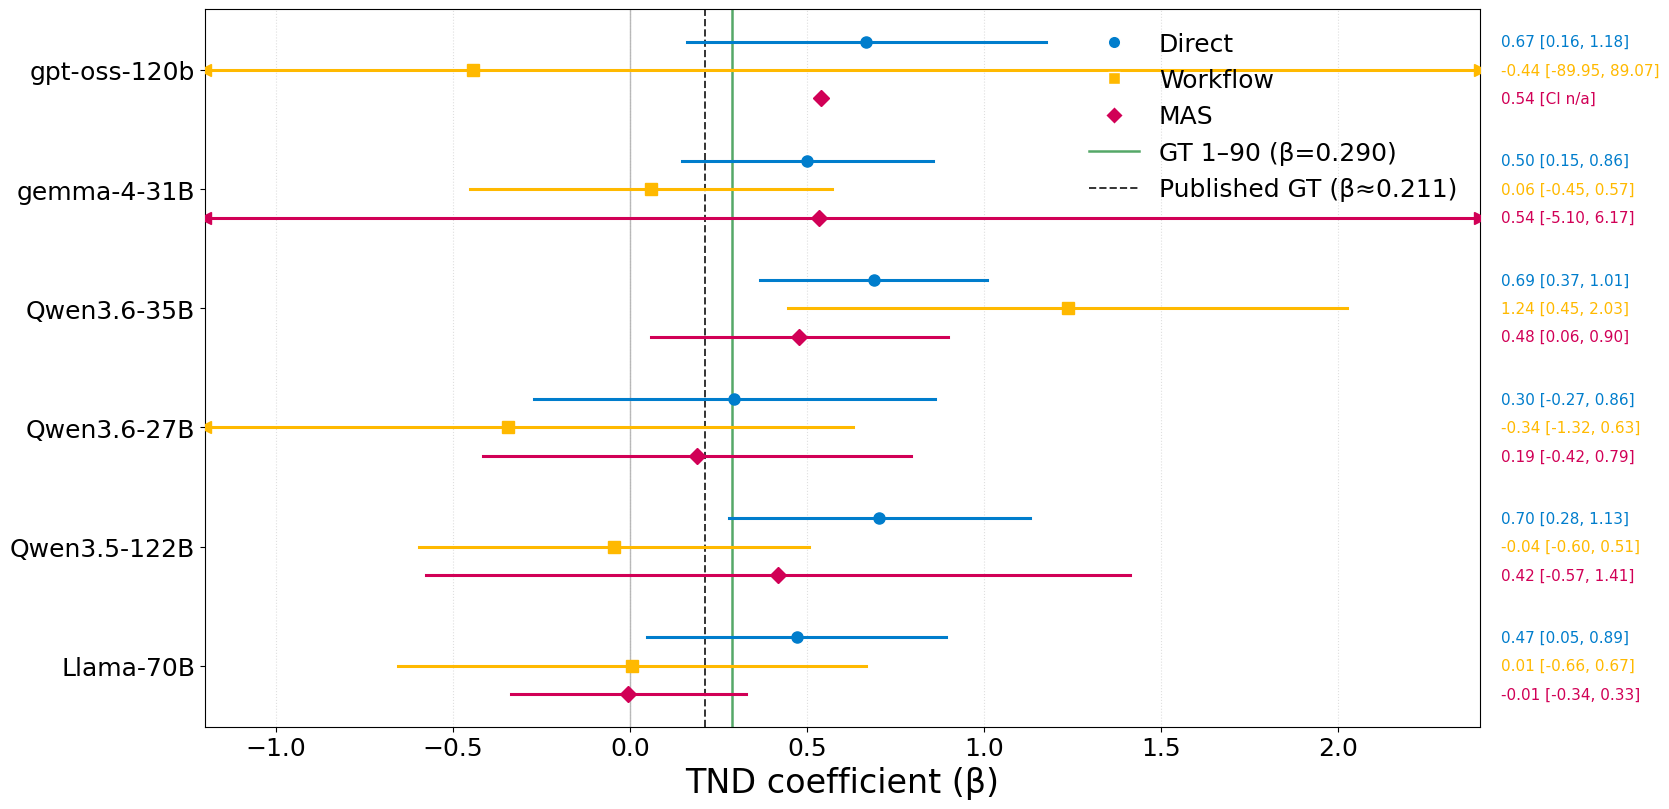

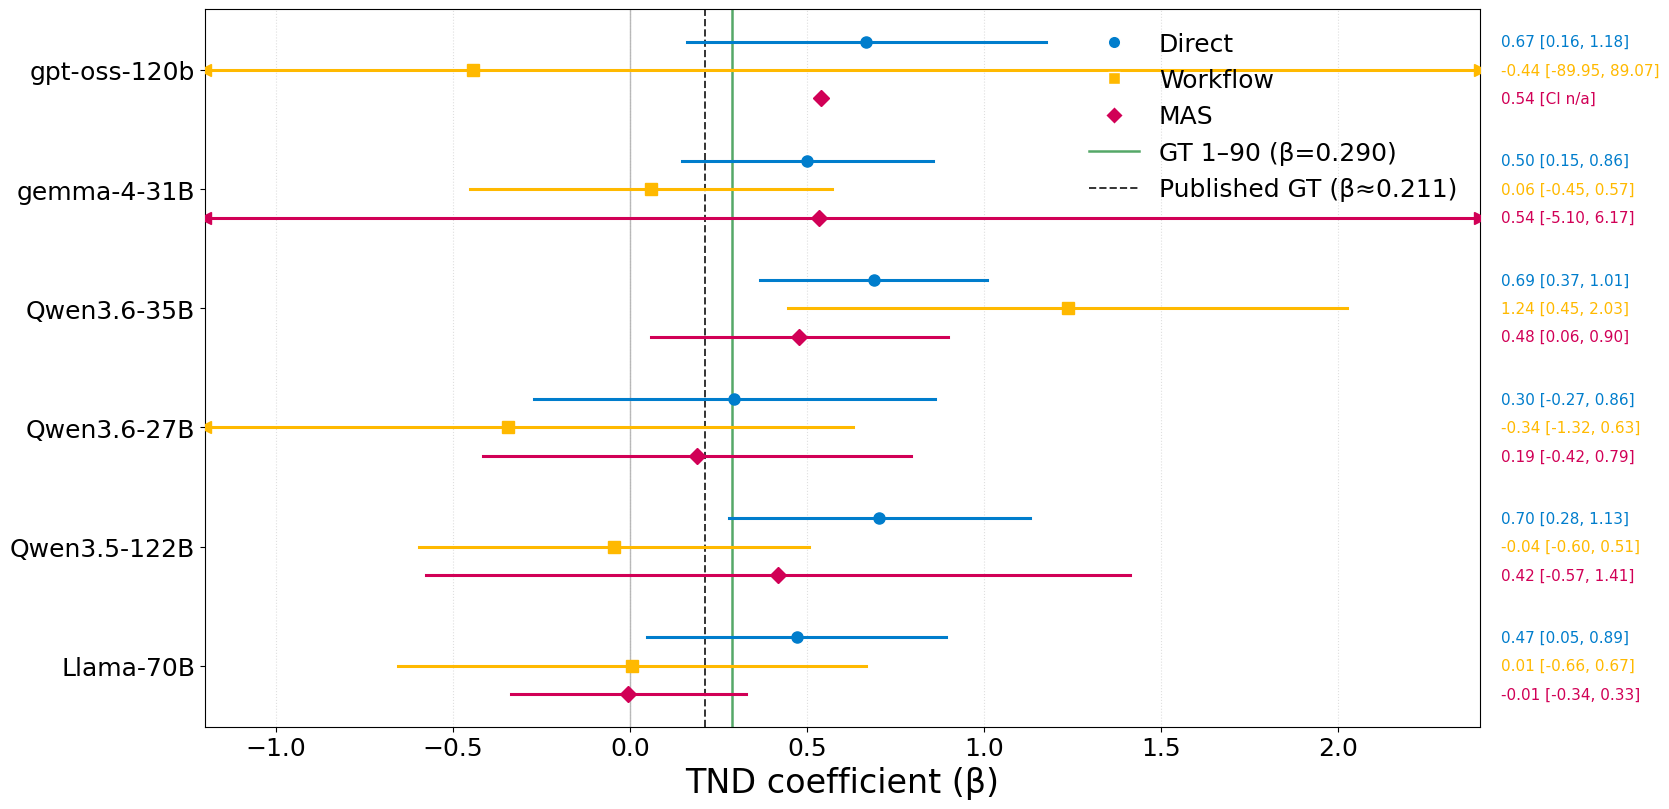

In [12]:
def plot_tnd_coefficients(
    summary: pd.DataFrame,
    baselines: dict,
    *,
    model_order: list[str] | None = None,
    methods=("direct_llm", "workflow", "MAS"),
    x_min: float = -1.2,
    x_max: float = 2.4,
):
    """Forest plot of TND β with 95% CI. Overflow CIs get arrows; β [CI] always labeled."""
    df = summary.copy()
    df["model_short"] = df["model_tag"].map(_short_model_title)
    if model_order is None:
        model_order = [_short_model_title(t) for t in all_runs]
    methods = [m for m in methods if m in set(df["method"])]

    n_models = len(model_order)
    n_methods = len(methods)
    group_gap = n_methods + 1.2
    y_ticks = []
    y_labels = []

    fig, ax = plt.subplots(figsize=(16.8, 8.2))
    gt = baselines["comparable_1_90"]
    pub = baselines.get("published_1_100")
    if pub is not None and math.isfinite(pub.tnd_coef):
        ax.axvline(pub.tnd_coef, color=GT_PUB_COLOR, ls="--", lw=1.4, zorder=1)
    if math.isfinite(gt.tnd_coef):
        ax.axvline(gt.tnd_coef, color=GT_COLOR, ls="-", lw=1.8, zorder=1)

    for mi, model in enumerate(model_order):
        base_y = (n_models - 1 - mi) * group_gap
        y_ticks.append(base_y + (n_methods - 1) / 2)
        y_labels.append(model)
        sub_m = df.loc[df["model_short"] == model]
        for ji, method in enumerate(methods):
            rows = sub_m.loc[sub_m["method"] == method]
            if rows.empty:
                continue
            r = rows.iloc[0]
            y = base_y + (n_methods - 1 - ji)
            coef = float(r["tnd_coef"])
            lo = float(r["tnd_ci_low"]) if pd.notna(r["tnd_ci_low"]) else float("nan")
            hi = float(r["tnd_ci_high"]) if pd.notna(r["tnd_ci_high"]) else float("nan")
            color = METHOD_PLOT_COLORS.get(method, "steelblue")
            marker = METHOD_MARKERS.get(method, "o")

            if math.isfinite(lo) and math.isfinite(hi):
                lo_c, hi_c = max(lo, x_min), min(hi, x_max)
                if hi_c >= lo_c:
                    ax.plot([lo_c, hi_c], [y, y], color=color, lw=2.2, zorder=3)
                if lo < x_min:
                    ax.plot(x_min, y, marker="<", color=color, markersize=9, zorder=4)
                if hi > x_max:
                    ax.plot(x_max, y, marker=">", color=color, markersize=9, zorder=4)
                ci_txt = f"{coef:.2f} [{lo:.2f}, {hi:.2f}]"
            else:
                ci_txt = f"{coef:.2f} [CI n/a]"

            x_pt = float(np.clip(coef, x_min, x_max)) if math.isfinite(coef) else x_min
            if math.isfinite(coef) and coef > x_max:
                marker = ">"
            elif math.isfinite(coef) and coef < x_min:
                marker = "<"
            ax.plot(x_pt, y, marker=marker, color=color, markersize=8, zorder=5)
            ax.text(
                x_max + 0.06,
                y,
                ci_txt,
                va="center",
                ha="left",
                fontsize=11,
                color=color,
                clip_on=False,
            )

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=TICK_LABELSIZE)
    ax.set_xlim(x_min, x_max)
    ax.set_xlabel("TND coefficient (β)", fontsize=AXIS_LABEL_FONTSIZE)
    ax.tick_params(axis="x", labelsize=TICK_LABELSIZE)
    ax.grid(axis="x", linestyle=":", alpha=0.4)
    ax.axvline(0.0, color="#bbbbbb", lw=1.0, zorder=0)

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker=METHOD_MARKERS[m],
            color="w",
            markerfacecolor=METHOD_PLOT_COLORS[m],
            markersize=9,
            label=METHOD_LABELS[m],
        )
        for m in methods
    ]
    legend_handles += [
        Line2D([0], [0], color=GT_COLOR, lw=1.8, label=f"GT 1–90 (β={gt.tnd_coef:.3f})"),
        Line2D(
            [0],
            [0],
            color=GT_PUB_COLOR,
            ls="--",
            lw=1.4,
            label=f"Published GT (β≈{pub.tnd_coef:.3f})" if pub is not None else "Published GT",
        ),
    ]
    ax.legend(handles=legend_handles, loc="upper right", fontsize=LEGEND_FONTSIZE, frameon=False)
    fig.tight_layout()
    plt.show()
    return fig


plot_tnd_coefficients(summary_df, BASELINES)